In [15]:
import pennylane as qml
from pennylane import numpy as np
import pandas as pd
from fractions import Fraction
from math import gcd

# Problema da Fatorização
Dado um inteiro $N$, encontra inteiros positivos $p_1, ..., p_m, r_1, ..., r_m$ tal que:

- Inteiros $p_1, ..., p_m$ são primos distintos;
- $N = \prod_{i=1}^m p_i ^ {r_i}$


Um algoritmo possível para o problema de fatorização é:
- Fatorizar $N$ em dois inteiros $p,q \in \,]1, N[$.
- Se $p$ e $q$ não forem primos, usar novamente o algoritmo até ficar só com números primos.


## Eliminar casos fáceis
Podemos assumir sem perda de generalidade que $N$ é ímpar, uma vez que se $N$ é par $p=2$, $q=N/2$.

Também existem algoritmos clássicos eficientes para verificar se $N = b^j$, para algum primo $b$ e inteiro $j>1$, pelo que esse caso pode ser tratado previamente e excluído da análise.


## Redução ao Problema da Procura de Ordem

O algoritmo de Shor baseia-se no facto de que a fatorização de $N$ pode ser reduzida ao problema de determinar a ordem.

### Ordem
Se $\gcd(a,N)=1$ (coprimos), a ordem de $a$ módulo $N$ é o menor inteiro positivo tal que:
$$
a^r \equiv 1\, (\text{mod }N)
$$

Se $r$ é ímpar, descartamos este $a$ e escolhemos outro aleatoriamente.

Logo,

$$
a^r \equiv 1 \Leftrightarrow a^r - 1 \equiv 0 \Leftrightarrow (a^{r/2}-1)(a^{r/2}+1) \equiv 0
$$

## Algoritmo

1. Escolher um inteiro $a \in ]1, N[$ aleatoriamente.
1. Calcular $d=\gcd(a,N)$.
    - Se $d$ é não trivial ($d \neq 1$): $p=d$, $q=N/d$. STOP
    
1. Usar a subrotina quântica para encontrar $r$.
1. Se $r$ é ímpar, voltar ao passo 1.
1. Calcular $x = \gcd(N, a^{r/2}-1)$ e $y = \gcd(N, a^{r/2}+1)$.
    - Se $1 < x < N$, então $p = x, q = N/x$. STOP
    - Se $1 < y < N$, então $p = y, q = N/y$. STOP
    
1. Voltar ao passo 1.


Note-se que o cálculo de $\gcd(a,N)$ é eficiente devido ao Algoritmo de Euclides.


## Subrotina Quântica
A subrotina quântica utilizada no algoritmo de Shor é o Algoritmo de Estimação Fase com 
$$
\ket{\psi}=\ket{1} \quad \quad U \ket{x} = \ket{ax(mod \,\,N)}
$$

O algoritmo usa dois registos, o 1º com $2n$ qubits e o 2º com $n$ qubits, $n = \lceil log_2 (N) \rceil$.

A execução do algoritmo mede um inteiro $0\leq k \lt 2^{2n}$, tal que:

$$
\frac{k}{2^{2n}}\approx \frac{s}{r}
$$

em que $s$ é um inteiro qualquer e $r$ é a ordem que queremos encontrar.

Isto é feito pelo Algoritmo das Frações Contínuas.

In [16]:
#@qml.transforms.decompose(max_expansion=3) #Para ver o circuito em detalhe

def shor_factoring(N, a):
    n = int(np.ceil(np.log2(N)))

    # H tensor 2n
    for i in range(2*n):
        qml.H(wires = i)

    qml.X(wires = 3*n-1) # O estado |1>

    # Construção da matriz U
    U = np.zeros((2**n, 2**n), dtype = int)

    for k in range(N):
        U[a*k % N, k] = 1

    U[N, N] = 1

    # Faz a sequência de gates controladas
    qml.ControlledSequence(qml.QubitUnitary(U, wires=range(2*n, 3*n)), control=range(2*n))

    qml.adjoint(qml.QFT)(wires=range(2*n))

    return qml.probs(wires=range(2*n))

## N = 15, a = 7

Teoricamente $a$ deve ser escolhido aleatoriamente. Aqui usamos um valor que já sabemos que funciona para ser mais fácil.


Mas claro que podia-se fazer isto (eu faço isto mais à frente com N=21):
```python
while True:
    a = np.random.randint(2, 20)
    if gcd(a, 21) == 1:
        break
 ```

(<Figure size 600x1300 with 1 Axes>, <Axes: >)

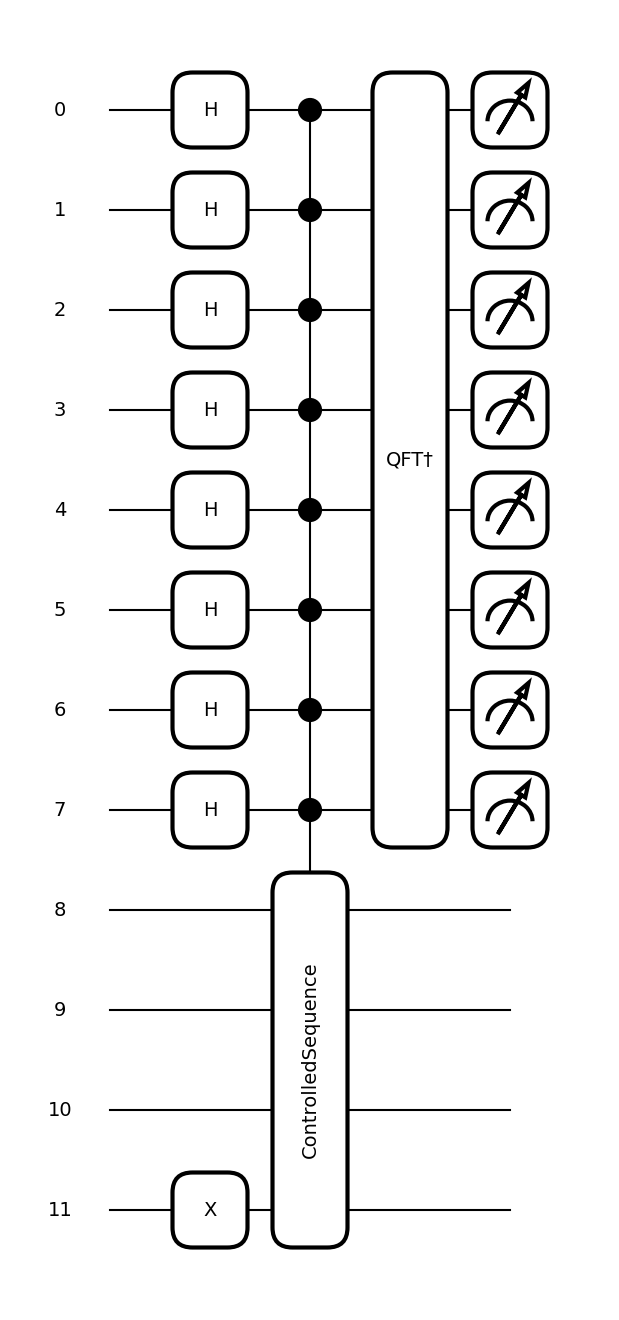

In [17]:
dev15 = qml.device("default.qubit", wires = 12)

qc15 = qml.QNode(shor_factoring, dev15)

qml.draw_mpl(qc15)(15, 7) 

In [18]:
print(int(np.ceil(np.log2(15))))

4


In [19]:
results = qc15(15, 7)
measured_phases = []

for i, x in enumerate(results):
    if x > 1e-9: # Por causa de erros de arredondamento
        print(i / 2**8)
        measured_phases.append(i / 2**8)

0.0
0.25
0.5
0.75


A ordem $r$ tem que ser menor que $N$ logo metemos esse limite.

In [20]:
rows = []
for phase in measured_phases:
    frac = Fraction(phase).limit_denominator(15) # Algoritmo de frações contínuas
    rows.append([phase,
                 f"{frac.numerator}/{frac.denominator}",
                 frac.denominator])
# Print as a table
headers=["Phase", "Fraction", "Guess for r"]
df = pd.DataFrame(rows, columns=headers)
print(df)

   Phase Fraction  Guess for r
0   0.00      0/1            1
1   0.25      1/4            4
2   0.50      1/2            2
3   0.75      3/4            4


Logo $r=4$.

In [21]:
x = gcd(15, 7**(4//2)-1)

y = gcd(15, 7**(4//2)+1)

print(x,y)

3 5


Logo $15=3*5$

# N = 21

In [22]:
print(int(np.ceil(np.log2(21))))

5


In [23]:
dev21 = qml.device("default.qubit", wires = 21)

qc21 = qml.QNode(shor_factoring, dev21)

In [24]:
'''
while True:
    a = np.random.randint(2, 20)
    if gcd(a, 21) == 1:
        break
'''
#Desta forma por tentativa e erro descobri que a = 8

results = qc21(21,8)
measured_phases = []

for i, x in enumerate(results):
    if x > 1e-9: # Por causa de erros de arredondamento
        #print(i / 2**10)
        measured_phases.append(i / 2**10)

rows = []
for phase in measured_phases:
    frac = Fraction(phase).limit_denominator(21) # Algoritmo de frações contínuas
    rows.append([phase,
                 f"{frac.numerator}/{frac.denominator}",
                 frac.denominator])
# Print as a table
headers=["Phase", "Fraction", "Guess for r"]
df = pd.DataFrame(rows, columns=headers)
print(df)

   Phase Fraction  Guess for r
0    0.0      0/1            1
1    0.5      1/2            2


Logo $r$ = 2.

In [25]:
x = gcd(21, 8**(2//2)-1)

y = gcd(21, 8**(2//2)+1)

print(x,y)

7 3


Logo $21 = 7*3$

# Problema do Logaritmo Discreto
Dado um grupo multiplicativo (por exemplo, definido por um primo $p$), com um gerador $g$ de ordem $q$ (conhecido) e um elemento $x$ pertencente a esse grupo, o objetivo é encontrar o logaritmo discreto de $x$, ou seja, o inteiro $\log_g(x)$ tal que:

- $0 \leq \log_g(x) < q$
- $g^{\log_g(x)} \equiv x \pmod p$

## Eliminar casos fáceis
Se $x = 1$, sabemos imediatamente que $\log_g(x) = 0$. Se $x = g$, sabemos que $\log_g(x) = 1$. Estes casos triviais podem ser verificados previamente e excluídos da análise.

## Redução ao Problema da Procura de Período (2D)

Para o cálculo do Logaritmo Discreto de $x = g^{\log_g(x)} \bmod p$, faz-se uso da função:

$$
f(a,b) = (x^a \cdot g^b) \bmod p
$$

A rotina quântica de cálculo de período de $f(-,-)$ irá encontrar um par $(\alpha,\beta)$ que estabeleça a congruência:

$$
(x^\alpha \cdot g^\beta) \bmod p = 1
$$

Sabendo nós que a ordem de $g$ é $q$, podemos exprimir a congruência nos expoentes, i.e.:

$$
\alpha \cdot \log_g(x) + \beta \bmod q = 0
$$

Note que existem $q$ pares $(\alpha,\beta)$ que satisfazem a equação, e que serão obtidos com igual probabilidade pela medição quântica.

## Algoritmo

1. Preparar três registos quânticos: os dois primeiros com $n$ qubits cada (onde $n = \lceil \log_2 (q) \rceil$) e o terceiro com tamanho suficiente para armazenar valores modulares até $p$.
2. Inicializar o estado em $\ket{0}\ket{0}\ket{0}$.
3. Aplicar $H^{\otimes 2n}$ nos dois primeiros registos.
4. Usar a subrotina quântica (o oráculo $U_f$) para calcular a função $f(a,b) = (x^a \cdot g^b) \bmod p$ no terceiro registo.
5. Aplicar a Transformada Quântica de Fourier Inversa (QFT Inversa) nos dois primeiros registos.
6. Medir os dois primeiros registos para obter o par $(\alpha, \beta)$.
7. Calcular o máximo divisor comum, $\gcd(\alpha, q)$:
    - Se $\gcd(\alpha, q) = 1$: podemos determinar o logaritmo discreto de $x$ como sendo $\log_g(x) = -\beta / \alpha \bmod q$. STOP.
    - Se $\gcd(\alpha, q) \neq 1$: não é possível calcular $\log_g(x)$, porque $\alpha$ não dispõe de inversa módulo $q$. Terá assim de se recorrer a outro par (voltar ao passo 2).

## Subrotina Quântica e QFT
A subrotina quântica utiliza um oráculo $U_f$ que atua sobre a base da seguinte forma:

$$
U_f \ket{a}\ket{b}\ket{0} = \ket{a}\ket{b}\ket{(x^a \cdot g^b) \bmod p}
$$

In [54]:
def shor_discrete_log(x, g, p, q):
    n = int(np.ceil(np.log2(q)))
    n_target = int(np.ceil(np.log2(p)))

    wires_a = list(range(n))
    wires_b = list(range(n, 2 * n))
    wires_target = list(range(2 * n, 2 * n + n_target))
    
    n_work = n_target + 2
    wires_work = list(range(2 * n + n_target, 2 * n + n_target + n_work))

    for i in wires_a + wires_b:
            qml.H(wires=i)

    qml.X(wires=wires_target[-1])

    # 3. Aplicar ModExp para x^a (Registo a)
    # Estado resultante: |a> |b> |1 * x^a mod p>
    qml.ModExp(wires_a, wires_target, base=x, mod=p, work_wires=wires_work)

    # 4. Aplicar ModExp para g^b (Registo b)
    # O valor já lá está (x^a), logo calcula: |a> |b> |(x^a) * g^b mod p>
    qml.ModExp(wires_b, wires_target, base=g, mod=p, work_wires=wires_work)

    # 5. Transformada de Fourier Inversa nos dois registos de entrada
    qml.adjoint(qml.QFT)(wires=range(2*n))

    return qml.probs(wires=range(2*n))

$x, g, p, q = 4, 2, 5, 4$

In [ ]:
x, g, p, q = 4, 2, 5, 4

n       = int(np.ceil(np.log2(q))) 
n_target = int(np.ceil(np.log2(p)))
n_work   = n_target + 2          


dev_dl = qml.device("lightning.qubit", wires = 2*n + n_target + n_work)

qc_dl = qml.QNode(shor_discrete_log, dev_dl)

results = qc_dl(4, 2, 5, 4)

In [71]:
for i, prob in enumerate(results):
    if prob > 1e-9:
        alpha = i >> n
        beta  = i & (2**n - 1)
        if alpha != 0 and gcd(alpha, q) == 1:
            inv_alpha = pow(alpha, -1, q)
            log_guess = (-beta * inv_alpha) % q
            if pow(g, log_guess, p) == x:
                print(f"Confirmado: log_{g}({x}) mod {p} = {log_guess}  (α={alpha}, β={beta}, prob={prob:.4f})")

Confirmado: log_2(4) mod 5 = 2  (α=1, β=2, prob=0.1250)
Confirmado: log_2(4) mod 5 = 2  (α=3, β=2, prob=0.1250)
